In [1]:
import zarr

In [2]:
import geff

In [3]:
arr = zarr.open('F:/4D cell tracking/biohub-cell-tracking-during-development/train/6bba_0c7fa718.zarr', mode='r')

In [4]:
list(arr.keys())

['0']

In [5]:
sub = arr['0']

In [6]:
sub.shape

(100, 64, 256, 256)

In [7]:
sub.chunks

(1, 64, 256, 256)

In [8]:
sub[0, 30]

array([[ 70,  77,  74, ...,  71,  56,  64],
       [ 70,  80,  69, ...,  65,  63,  73],
       [ 61,  68,  69, ...,  68,  73,  66],
       ...,
       [350, 316, 311, ..., 509, 515, 525],
       [337, 330, 333, ..., 493, 493, 475],
       [327, 324, 323, ..., 501, 501, 476]],
      shape=(256, 256), dtype=uint16)

In [9]:
import cv2

In [10]:
#display the image sub[0] using cv2.imshow
cv2.imshow('image', sub[0, 50])
cv2.waitKey(0)
cv2.destroyAllWindows()

In [11]:
import numpy as np

def normalize_for_display(img, low_pct=1, high_pct=99):
    lo, hi = np.percentile(img, [low_pct, high_pct])
    img_norm = np.clip((img.astype(np.float32) - lo) / (hi - lo), 0, 1)
    return (img_norm * 255).astype(np.uint8)

z_slice = sub[0, 63]
display_img = normalize_for_display(z_slice)

cv2.imshow('image', display_img)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [12]:
import numpy as np

def normalize_for_display(img, low_pct=1, high_pct=99):
    lo, hi = np.percentile(img, [low_pct, high_pct])
    img_norm = np.clip((img.astype(np.float32) - lo) / (hi - lo), 0, 1)
    return (img_norm * 255).astype(np.uint8)

z_slice = sub[1, 63]
display_img = normalize_for_display(z_slice)

cv2.imshow('image', display_img)
cv2.waitKey(0)
cv2.destroyAllWindows()

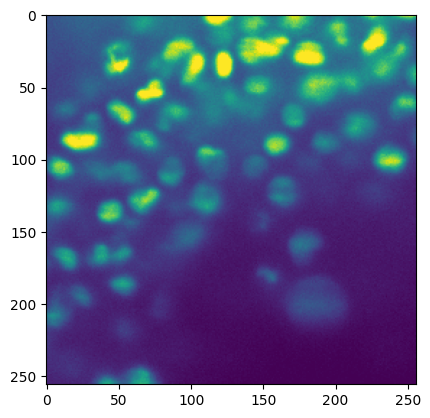

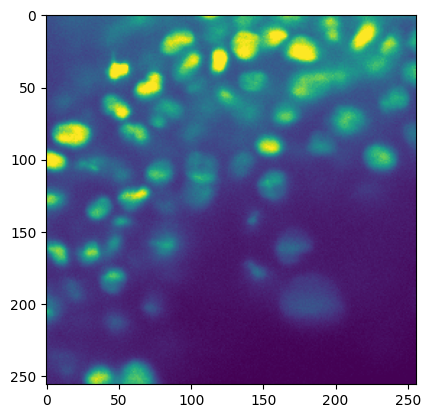

In [13]:
#display image sub[0, 63] using matplotlib with normalized display
import matplotlib.pyplot as plt

display_img1 = normalize_for_display(sub[0, 63])
plt.imshow(display_img1)
plt.show()

display_img2 = normalize_for_display(sub[1, 63])
plt.imshow(display_img2)
plt.show()

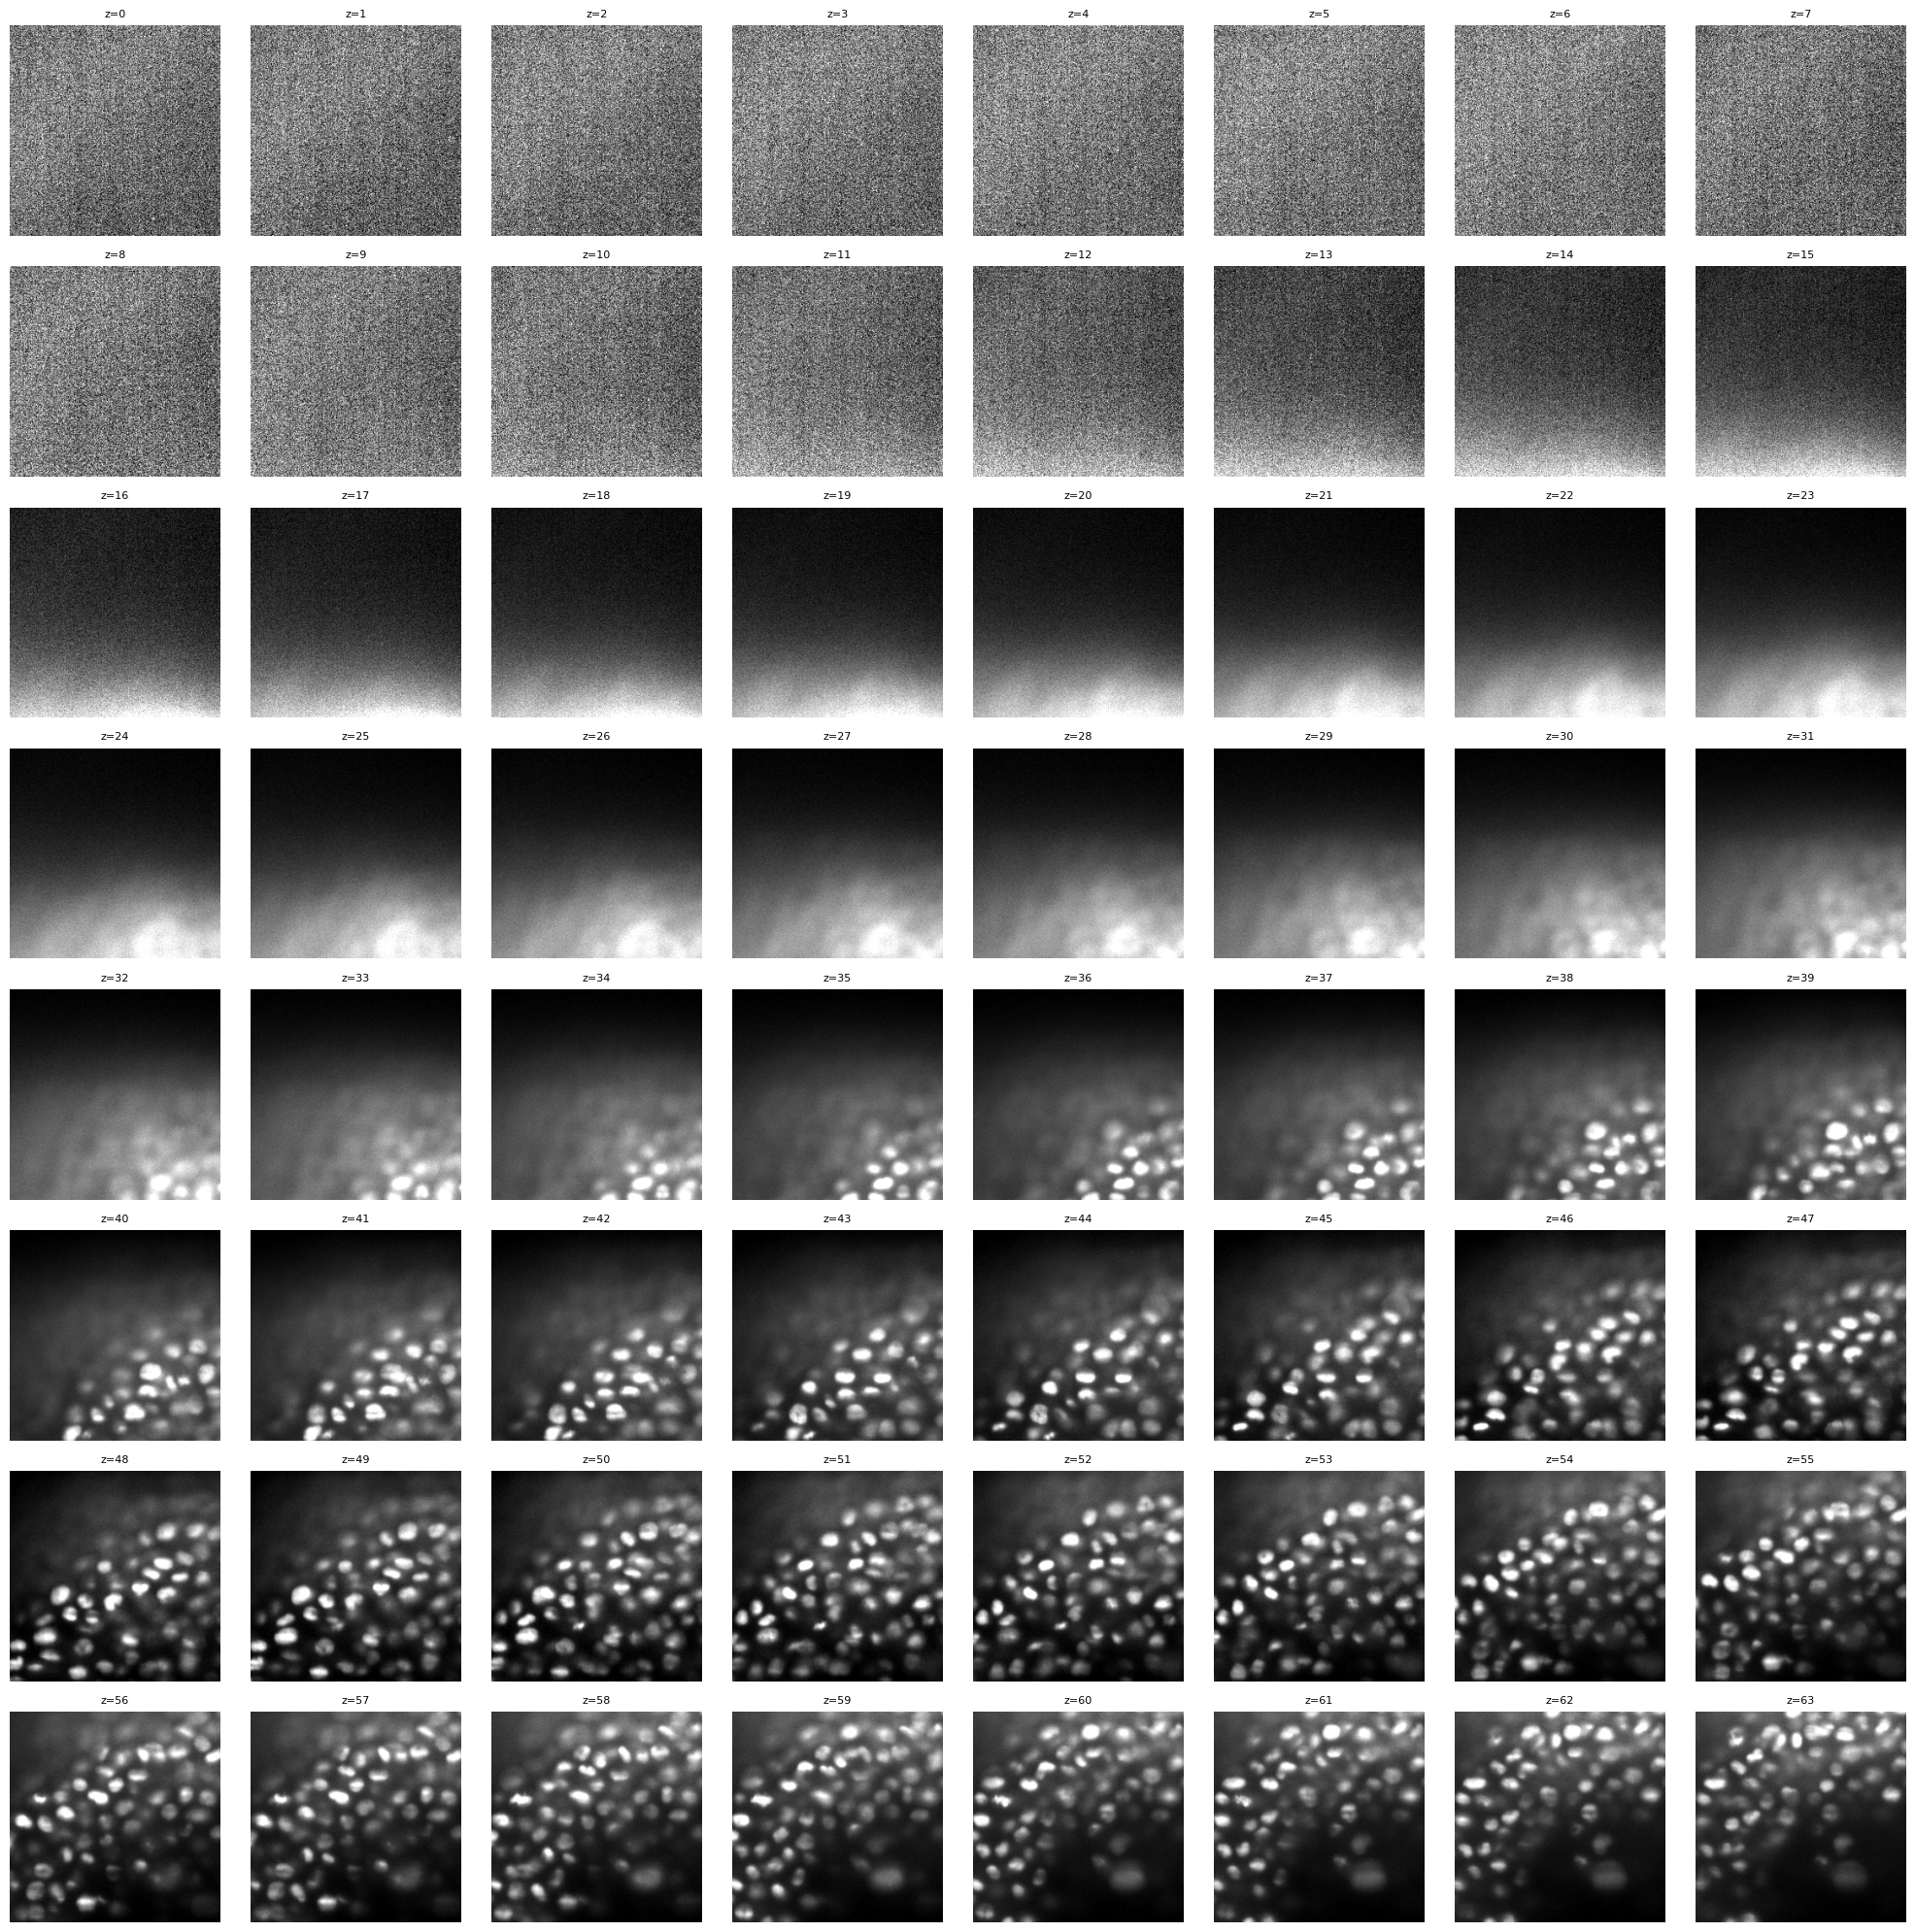

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(8, 8, figsize=(20, 20))

for z in range(64):
    row, col = divmod(z, 8)
    img = normalize_for_display(sub[0, z])
    axes[row, col].imshow(img, cmap='gray')
    axes[row, col].set_title(f'z={z}', fontsize=8)
    axes[row, col].axis('off')

plt.tight_layout()
plt.show()

In [15]:
import geff

graph, metadata = geff.read(r'biohub-cell-tracking-during-development\train\6bba_0c7fa718.geff', backend='networkx')

print(type(graph))      # should be networkx.DiGraph or similar
print(metadata)         # GeffMetadata object - axis names, units, etc.

<class 'networkx.classes.digraph.DiGraph'>
geff_version='1.1' directed=True axes=[Axis(name='t', type='time', unit=None, min=0.0, max=99.0, scale=1.0, scaled_unit=None, offset=None), Axis(name='z', type='space', unit=None, min=17.0, max=62.0, scale=1.625, scaled_unit=None, offset=None), Axis(name='y', type='space', unit=None, min=2.0, max=253.0, scale=0.40625, scaled_unit=None, offset=None), Axis(name='x', type='space', unit=None, min=4.0, max=252.0, scale=0.40625, scaled_unit=None, offset=None)] node_props_metadata={'t': PropMetadata(identifier='t', dtype='int64', varlength=False, unit=None, name=None, description=None), 'z': PropMetadata(identifier='z', dtype='int64', varlength=False, unit=None, name=None, description=None), 'y': PropMetadata(identifier='y', dtype='int64', varlength=False, unit=None, name=None, description=None), 'x': PropMetadata(identifier='x', dtype='int64', varlength=False, unit=None, name=None, description=None)} edge_props_metadata={} sphere=None ellipsoid=None

In [16]:
result = geff.read(r'biohub-cell-tracking-during-development\train\6bba_0c7fa718.geff', backend='networkx')
print(len(result))
print(type(result[0]), type(result[1]))

2
<class 'networkx.classes.digraph.DiGraph'> <class 'geff_spec._schema.GeffMetadata'>


In [17]:
print(list(graph.nodes)[:5])   # peek at a few node ids
print(graph.number_of_nodes(), graph.number_of_edges())

[1000002, 1000004, 1000007, 1000011, 1000012]
704 659


In [18]:
list(graph.nodes)

[1000002,
 1000004,
 1000007,
 1000011,
 1000012,
 1000017,
 1000019,
 1000020,
 1000021,
 2000035,
 2000038,
 2000039,
 2000043,
 2000044,
 2000050,
 2000052,
 2000054,
 2000058,
 3000065,
 3000067,
 3000071,
 3000072,
 3000073,
 3000079,
 3000081,
 3000087,
 3000089,
 4000096,
 4000098,
 4000099,
 4000100,
 4000102,
 4000109,
 4000111,
 4000112,
 4000114,
 5000126,
 5000127,
 5000131,
 5000133,
 5000135,
 5000142,
 5000143,
 5000144,
 5000149,
 6000157,
 6000158,
 6000159,
 6000163,
 6000167,
 6000169,
 6000171,
 6000177,
 6000178,
 6000181,
 7000192,
 7000193,
 7000194,
 7000198,
 7000199,
 7000203,
 7000205,
 7000211,
 7000212,
 7000214,
 8000228,
 8000230,
 8000232,
 8000233,
 8000234,
 8000238,
 8000242,
 8000245,
 8000247,
 8000249,
 8000250,
 9000257,
 9000264,
 9000266,
 9000268,
 9000269,
 9000271,
 9000272,
 9000277,
 9000283,
 9000285,
 9000287,
 10000291,
 10000297,
 10000299,
 10000302,
 10000304,
 10000308,
 10000309,
 10000310,
 10000311,
 10000317,
 10000318,
 10000321

In [19]:
node_data = graph.nodes[1000021]
nodes_at_t10 = [n for n, d in graph.nodes(data=True) if d['t'] == 10]
successors = list(graph.successors(1000021))
print(node_data)
print(nodes_at_t10)
print(successors)

{'t': 0, 'z': 55, 'y': 194, 'x': 126}
[11000336, 11000342, 11000345, 11000347, 11000348, 11000349, 11000350, 11000351, 11000352, 11000355, 11000357, 11000359]
[2000058]


433


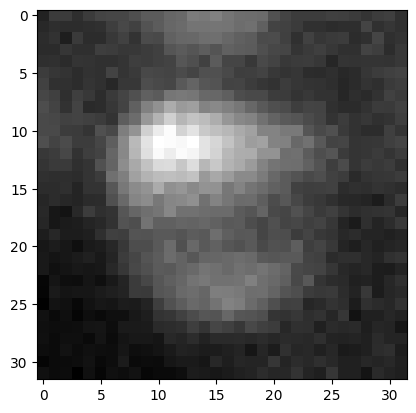

In [20]:
node_data = graph.nodes[1000021]
t, z, y, x = node_data['t'], node_data['z'], node_data['y'], node_data['x']

# the raw intensity at exactly that point
print(sub[t, z, y, x])

# a patch around it, e.g. 32x32 crop centered on the nucleus
half = 16
patch = sub[t, z, y-half:y+half, x-half:x+half]

#plot the image and its patch using matplotlib
plt.imshow(sub[t, z, :, :], cmap='gray')
plt.imshow(patch, cmap='gray')
plt.show()

In [21]:
import napari

In [22]:
viewer = napari.Viewer()
viewer.dims.ndisplay = 3   # switch from 2D-slice mode to full 3D rendering
viewer.add_image(sub, name='raw')
import numpy as np

# napari points want shape (N, ndim) matching the image's axes order: T, Z, Y, X
points = np.array([[d['t'], d['z'], d['y'], d['x']] for n, d in graph.nodes(data=True)])
viewer.add_points(points, name='cells', size=5, face_color='red')
napari.run()

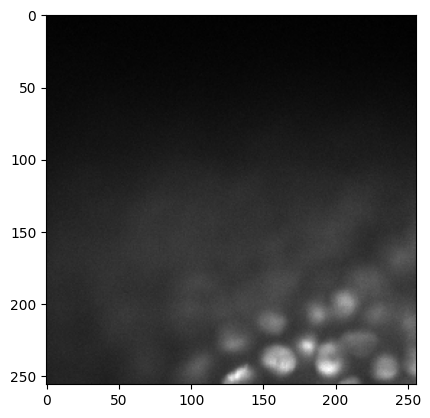

In [23]:
import matplotlib.pyplot as plt

t, z = 10, 32
slice_2d = sub[t, z]
cells_here = [(d['y'], d['x']) for n, d in graph.nodes(data=True) if d['t']==t and d['z']==z]

plt.imshow(slice_2d, cmap='gray')
ys, xs = zip(*cells_here) if cells_here else ([],[])
plt.scatter(xs, ys, c='red', s=10)

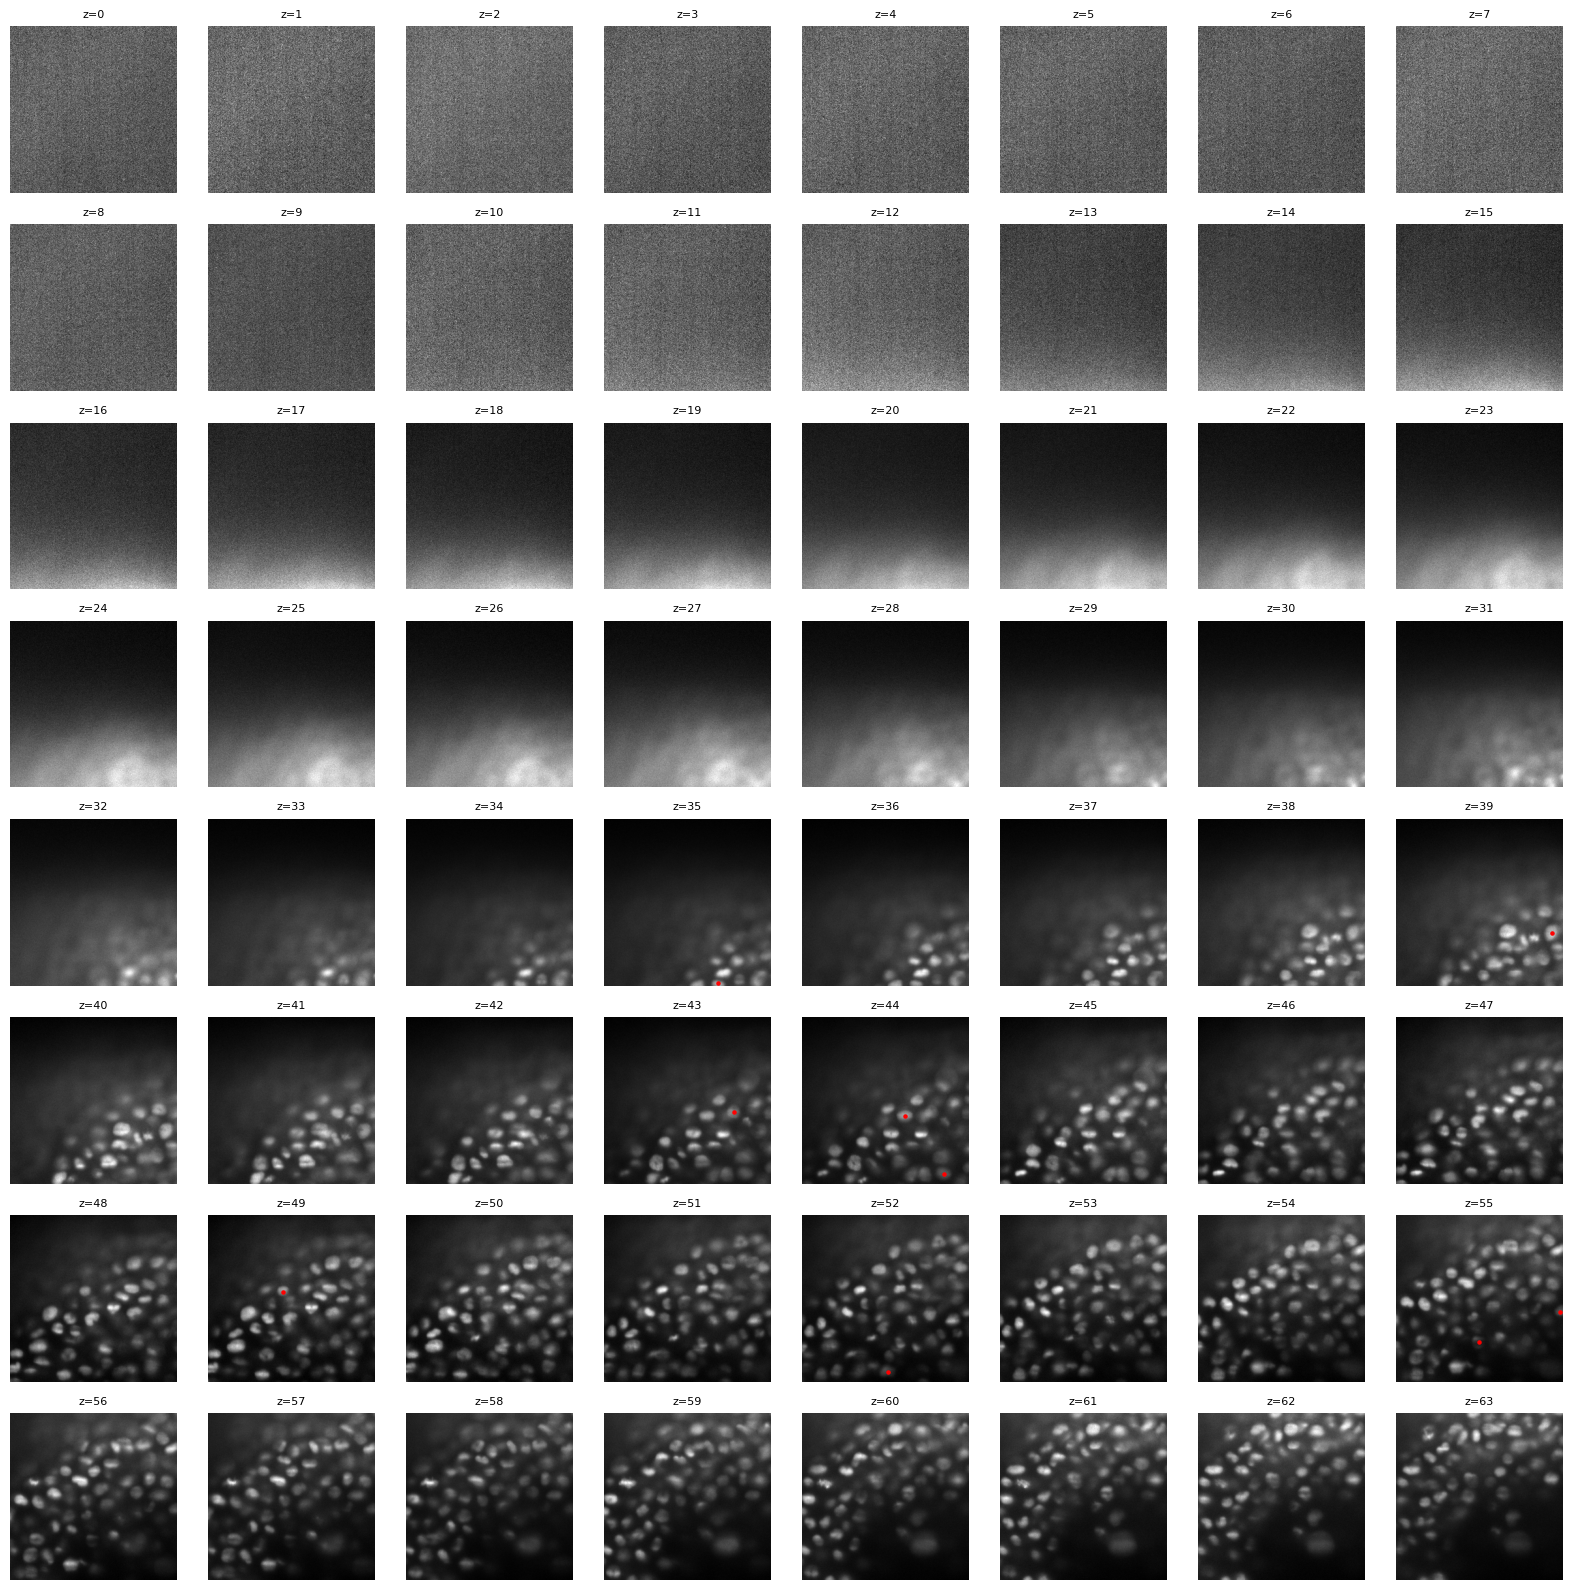

In [24]:
import matplotlib.pyplot as plt

t = 0
n_z = sub.shape[1]   # 64

# grid layout: e.g. 8 rows x 8 cols for 64 slices
n_cols = 8
n_rows = -(-n_z // n_cols)  # ceil division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*2, n_rows*2))
axes = axes.flatten()

for z in range(n_z):
    slice_2d = sub[t, z]
    cells_here = [(d['y'], d['x']) for n, d in graph.nodes(data=True)
                  if d['t'] == t and d['z'] == z]

    ax = axes[z]
    ax.imshow(slice_2d, cmap='gray')
    if cells_here:
        ys, xs = zip(*cells_here)
        ax.scatter(xs, ys, c='red', s=5)
    ax.set_title(f"z={z}", fontsize=8)
    ax.axis('off')

# hide any unused subplot slots
for ax in axes[n_z:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

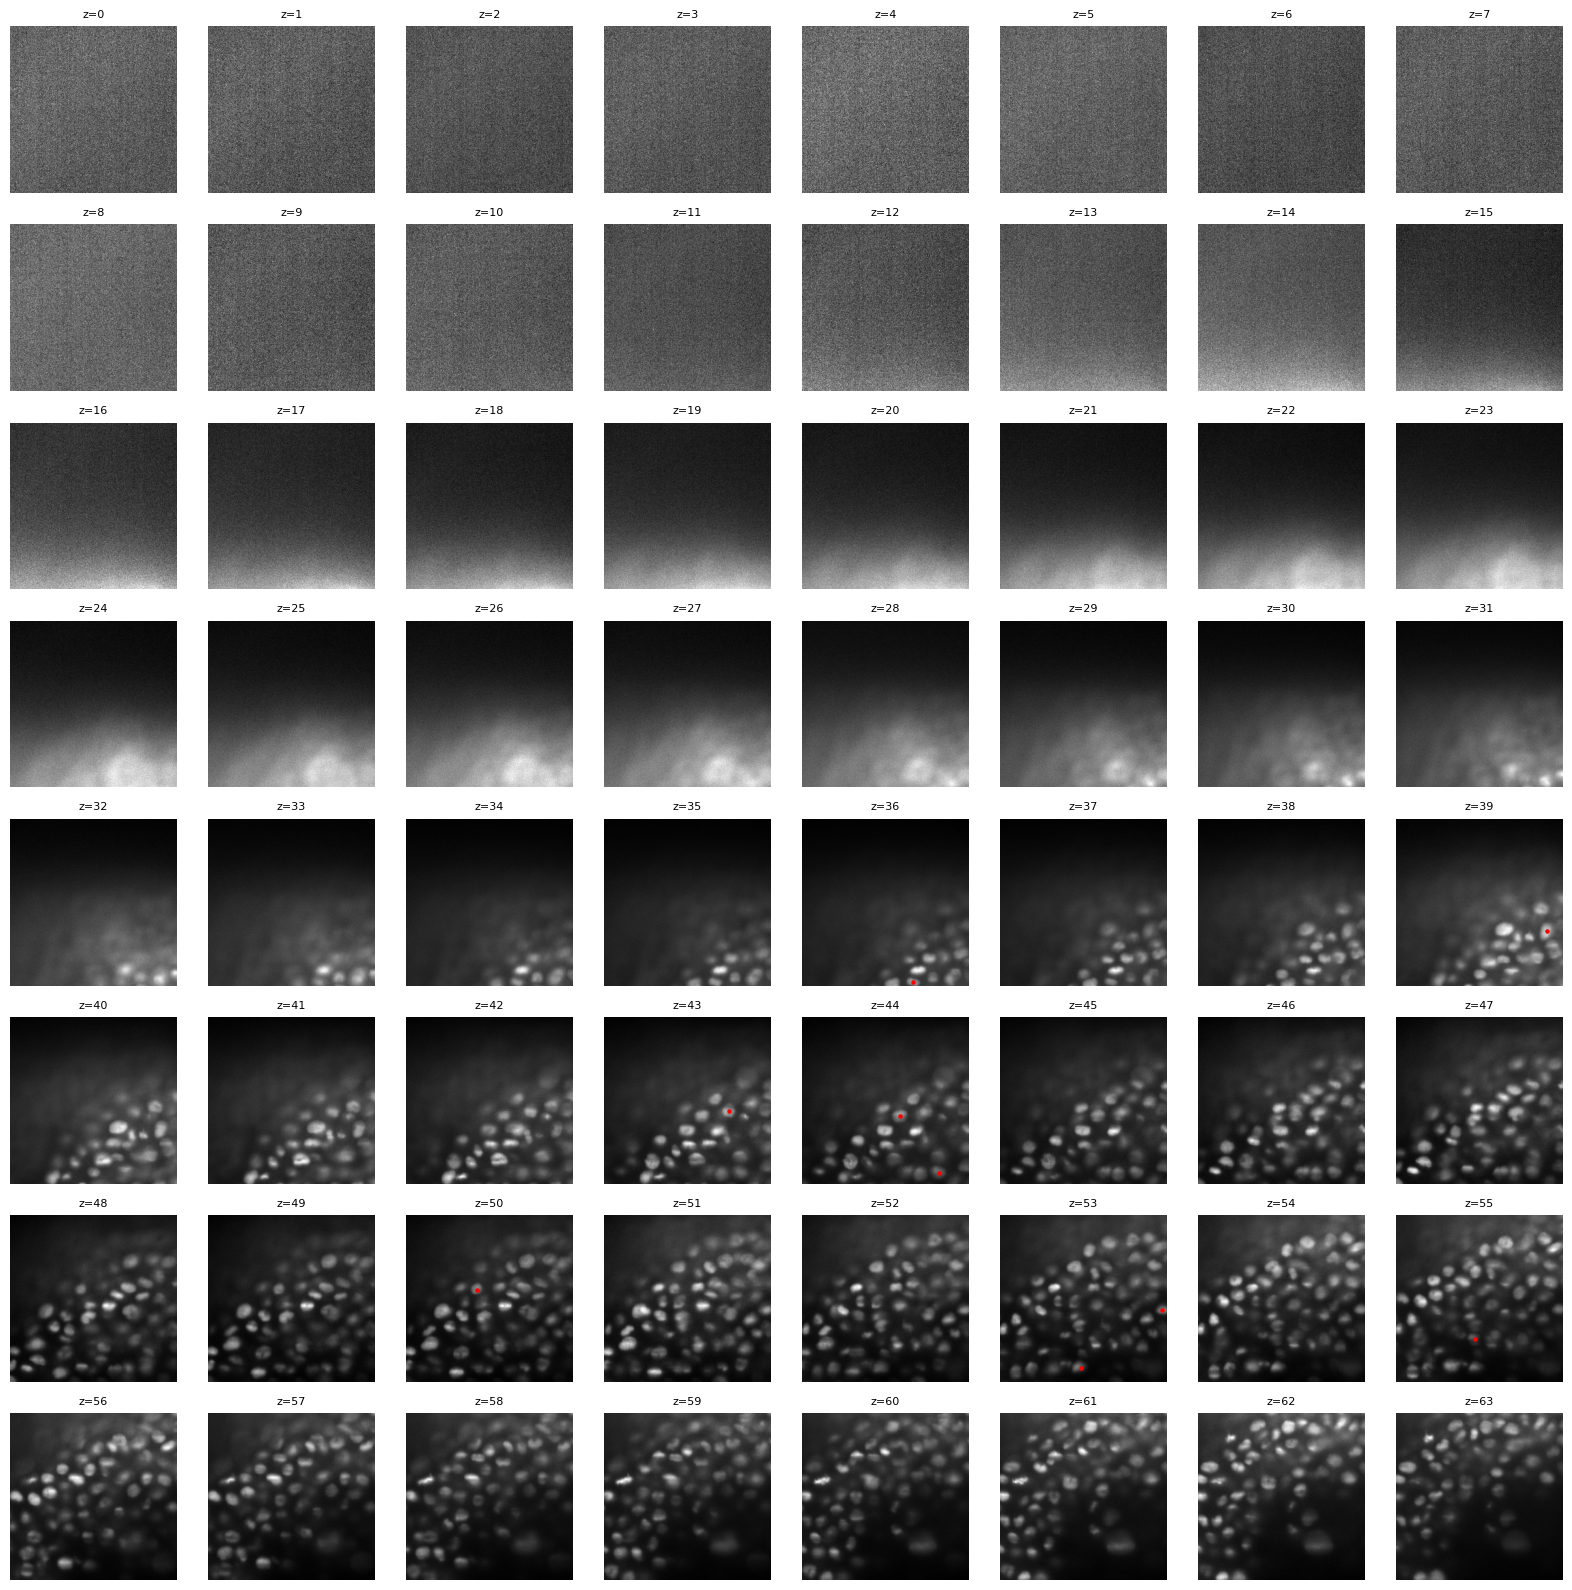

In [25]:
import matplotlib.pyplot as plt

t = 1
n_z = sub.shape[1]   # 64

# grid layout: e.g. 8 rows x 8 cols for 64 slices
n_cols = 8
n_rows = -(-n_z // n_cols)  # ceil division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*2, n_rows*2))
axes = axes.flatten()

for z in range(n_z):
    slice_2d = sub[t, z]
    cells_here = [(d['y'], d['x']) for n, d in graph.nodes(data=True)
                  if d['t'] == t and d['z'] == z]

    ax = axes[z]
    ax.imshow(slice_2d, cmap='gray')
    if cells_here:
        ys, xs = zip(*cells_here)
        ax.scatter(xs, ys, c='red', s=5)
    ax.set_title(f"z={z}", fontsize=8)
    ax.axis('off')

# hide any unused subplot slots
for ax in axes[n_z:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

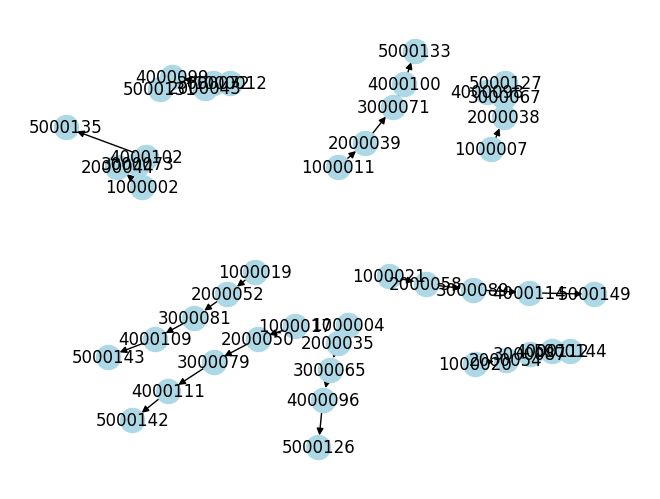

In [26]:
import networkx as nx
import matplotlib.pyplot as plt

# Usually only meaningful for a SMALL subgraph - e.g. one cell's lineage
small_graph = graph.subgraph([n for n, d in graph.nodes(data=True) if d['t'] < 5])

pos = nx.spring_layout(small_graph)  # abstract layout, not spatial
nx.draw(small_graph, pos, with_labels=True, node_size=300, node_color='lightblue')
plt.show()

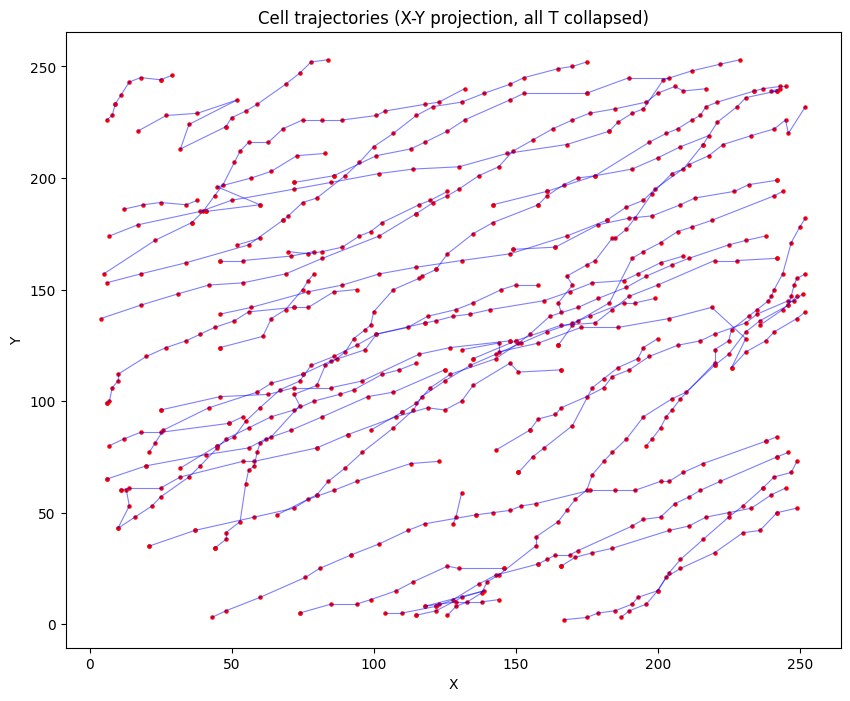

In [27]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))

for u, v in graph.edges():
    du, dv = graph.nodes[u], graph.nodes[v]
    ax.plot([du['x'], dv['x']], [du['y'], dv['y']], 'b-', alpha=0.5, linewidth=0.8)

xs = [d['x'] for n, d in graph.nodes(data=True)]
ys = [d['y'] for n, d in graph.nodes(data=True)]
ax.scatter(xs, ys, c='red', s=5)

ax.set_xlabel('X'); ax.set_ylabel('Y')
ax.set_title('Cell trajectories (X-Y projection, all T collapsed)')
plt.show()

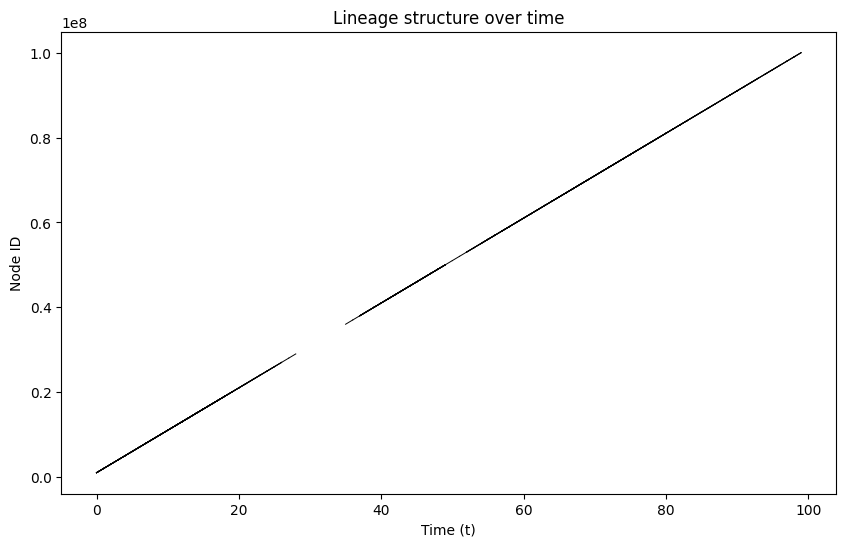

In [28]:
fig, ax = plt.subplots(figsize=(10, 6))

for u, v in graph.edges():
    du, dv = graph.nodes[u], graph.nodes[v]
    ax.plot([du['t'], dv['t']], [u, v], 'k-', linewidth=0.7)  # y-axis = node id (arbitrary but consistent)

ax.set_xlabel('Time (t)')
ax.set_ylabel('Node ID')
ax.set_title('Lineage structure over time')
plt.show()

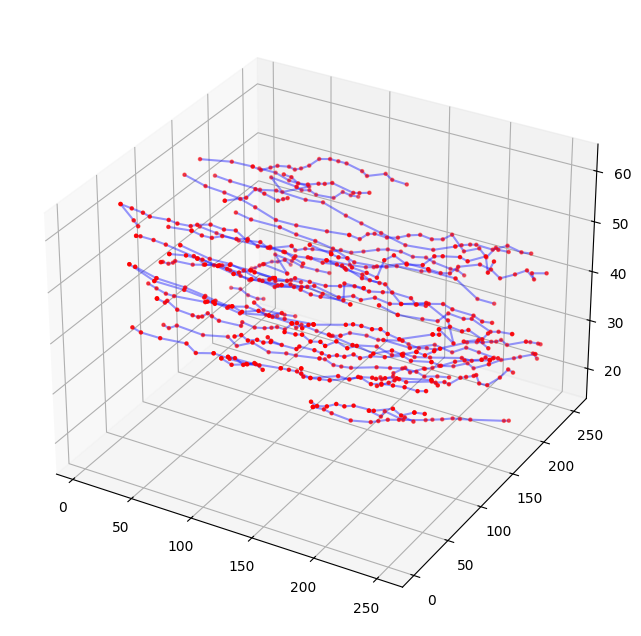

In [29]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')

for u, v in graph.edges():
    du, dv = graph.nodes[u], graph.nodes[v]
    ax.plot([du['x'], dv['x']], [du['y'], dv['y']], [du['z'], dv['z']], 'b-', alpha=0.4)

ax.scatter(xs, ys, [d['z'] for n,d in graph.nodes(data=True)], c='red', s=5)
plt.show()


In [30]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Each connected component = one full lineage (root cell + all its descendants)
components = list(nx.weakly_connected_components(graph))
print(f"{len(components)} separate lineages found")

# Assign a color per component
cmap = cm.get_cmap('tab20', len(components))
node_to_color = {}
for i, comp in enumerate(components):
    color = cmap(i)
    for node in comp:
        node_to_color[node] = color

45 separate lineages found


C:\Users\Raghava\AppData\Local\Temp\ipykernel_33140\210249449.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20', len(components))


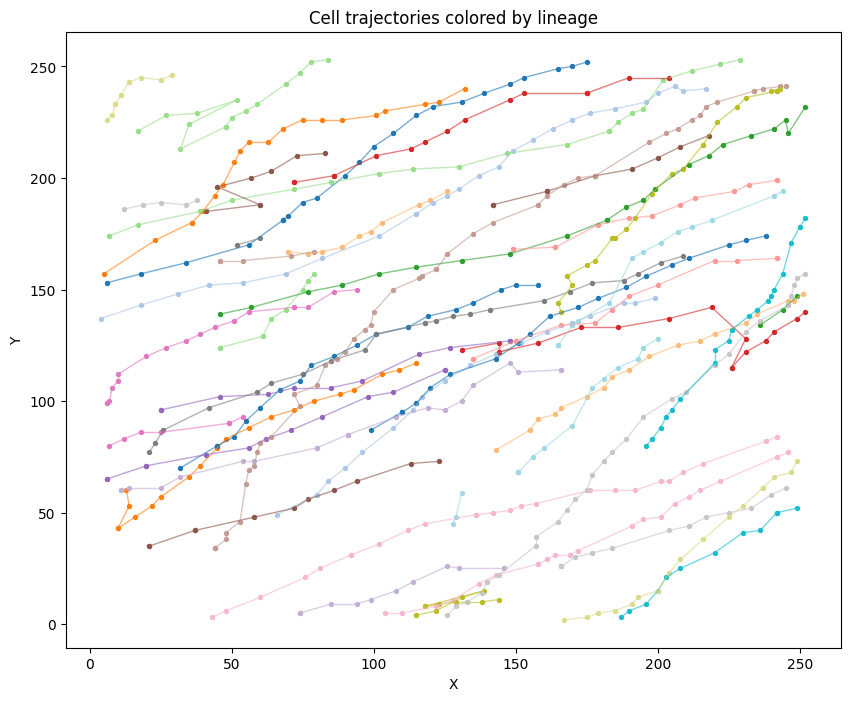

In [31]:
fig, ax = plt.subplots(figsize=(10, 8))

for u, v in graph.edges():
    du, dv = graph.nodes[u], graph.nodes[v]
    color = node_to_color[u]   # u and v are always same component, so either works
    ax.plot([du['x'], dv['x']], [du['y'], dv['y']], color=color, alpha=0.6, linewidth=1)

for n, d in graph.nodes(data=True):
    ax.scatter(d['x'], d['y'], color=node_to_color[n], s=8)

ax.set_xlabel('X'); ax.set_ylabel('Y')
ax.set_title('Cell trajectories colored by lineage')
plt.show()

C:\Users\Raghava\AppData\Local\Temp\ipykernel_33140\2900613623.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20', len(components))


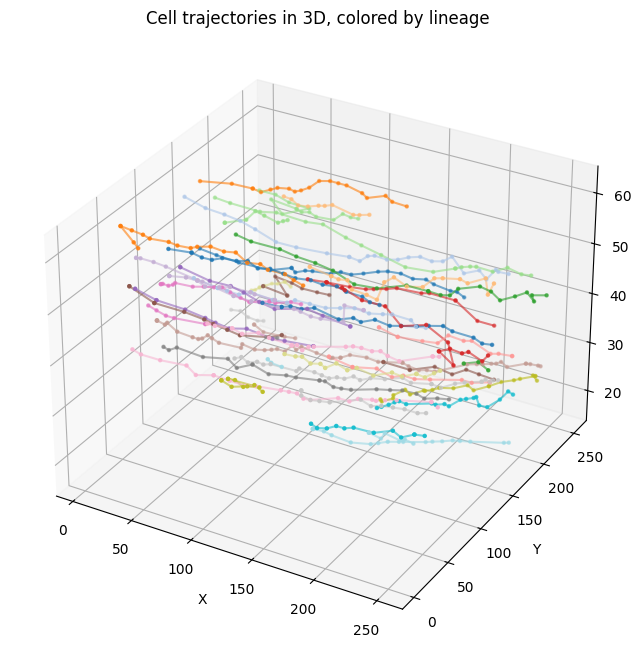

In [32]:
import matplotlib.cm as cm
from mpl_toolkits.mplot3d import Axes3D

components = list(nx.weakly_connected_components(graph))
cmap = cm.get_cmap('tab20', len(components))
node_to_color = {}
for i, comp in enumerate(components):
    color = cmap(i)
    for node in comp:
        node_to_color[node] = color

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')

for u, v in graph.edges():
    du, dv = graph.nodes[u], graph.nodes[v]
    color = node_to_color[u]
    ax.plot([du['x'], dv['x']], [du['y'], dv['y']], [du['z'], dv['z']], color=color, alpha=0.6)

xs = [d['x'] for n, d in graph.nodes(data=True)]
ys = [d['y'] for n, d in graph.nodes(data=True)]
zs = [d['z'] for n, d in graph.nodes(data=True)]
colors = [node_to_color[n] for n in graph.nodes()]

ax.scatter(xs, ys, zs, c=colors, s=5)

ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z')
ax.set_title('Cell trajectories in 3D, colored by lineage')
plt.show()

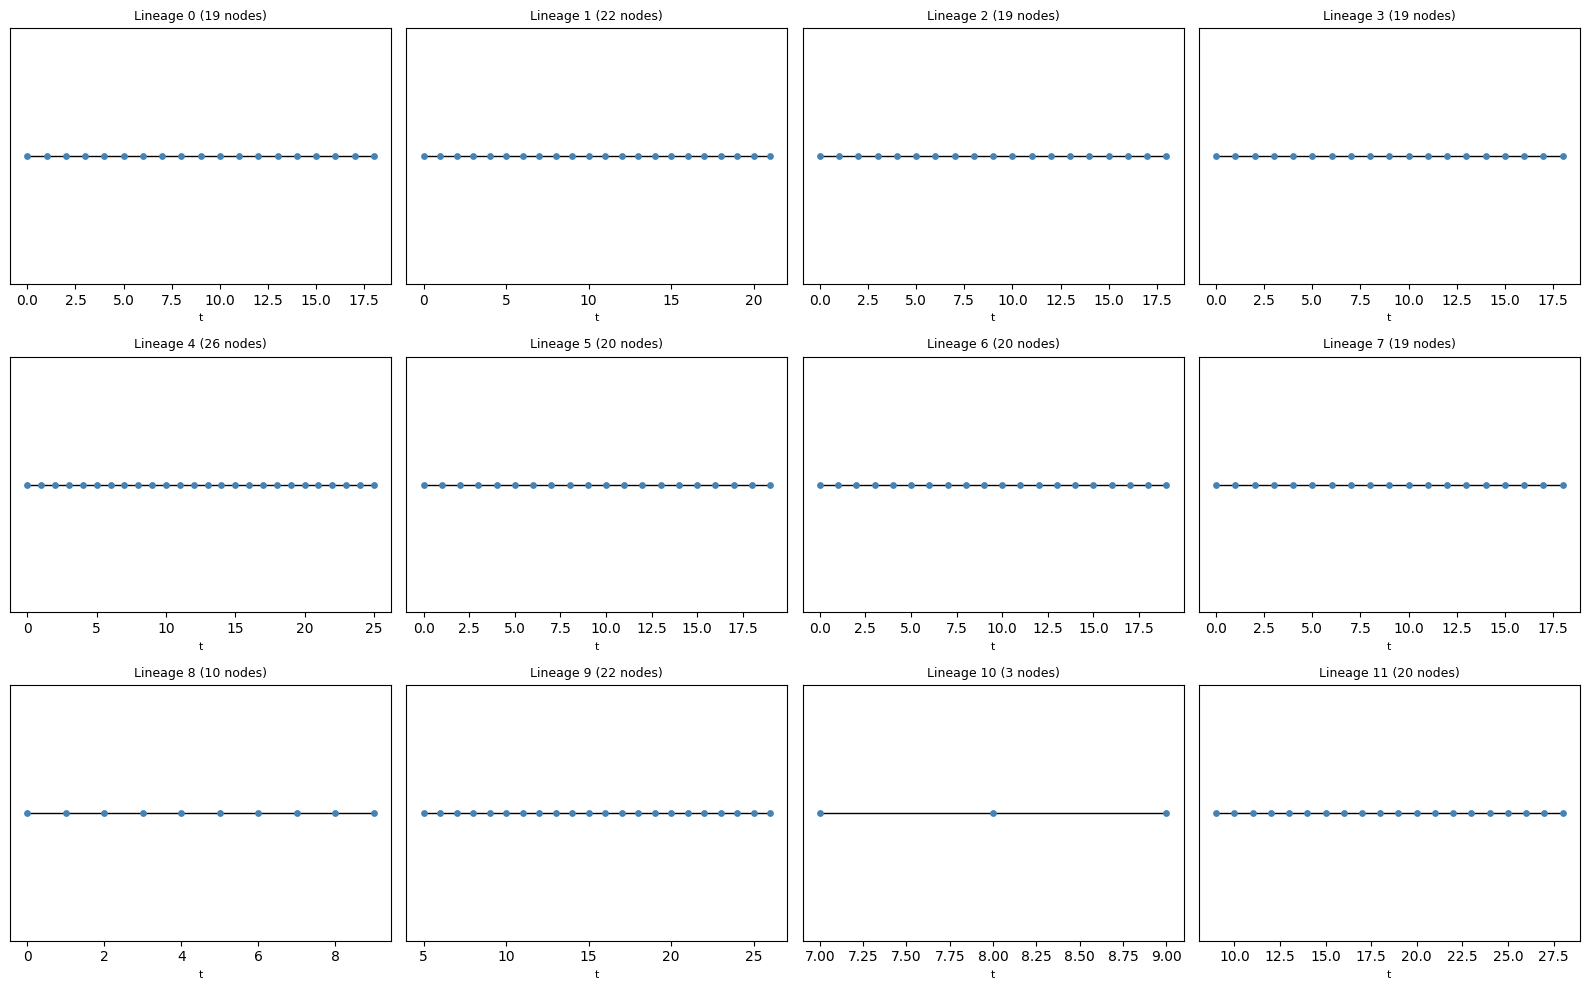

In [33]:
def assign_lanes(tree, root):
    """Recursively assign a y-position (lane) to every node in one lineage tree."""
    positions = {}
    leaf_counter = [0]  # mutable counter shared across recursive calls

    def recurse(node):
        children = list(tree.successors(node))
        if not children:
            positions[node] = leaf_counter[0]
            leaf_counter[0] += 1
        else:
            for c in children:
                recurse(c)
            positions[node] = sum(positions[c] for c in children) / len(children)

    recurse(root)
    return positions

# Plot each lineage as its own small tree
components = list(nx.weakly_connected_components(graph))
n_show = min(len(components), 12)  # cap for readability - adjust as needed

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for i, comp in enumerate(components[:n_show]):
    subtree = graph.subgraph(comp)
    root = [n for n in subtree.nodes() if subtree.in_degree(n) == 0][0]  # find the ancestor
    lanes = assign_lanes(subtree, root)

    ax = axes[i]
    for u, v in subtree.edges():
        du, dv = subtree.nodes[u], subtree.nodes[v]
        ax.plot([du['t'], dv['t']], [lanes[u], lanes[v]], 'k-', linewidth=1)

    for n, d in subtree.nodes(data=True):
        ax.scatter(d['t'], lanes[n], s=15, color='steelblue', zorder=3)

    ax.set_title(f'Lineage {i} ({len(comp)} nodes)', fontsize=9)
    ax.set_xlabel('t', fontsize=8)
    ax.set_yticks([])  # lane numbers are arbitrary, hide them

for ax in axes[n_show:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [34]:
# napari tracks format: [track_id, t, z, y, x]
# track_id here = which lineage/component the node belongs to
track_id_map = {node: i for i, comp in enumerate(components) for node in comp}

tracks_data = [[track_id_map[n], d['t'], d['z'], d['y'], d['x']]
               for n, d in graph.nodes(data=True)]

import numpy as np
tracks_data = np.array(tracks_data)

viewer.add_tracks(tracks_data, name='lineages')  # auto-colors by track_id
viewer.dims.ndisplay = 3

In [35]:
import zarr
from geff import read
import networkx as nx
from pathlib import Path
import pandas as pd

train_dir = Path(r"biohub-cell-tracking-during-development\train")
zarr_files = sorted(train_dir.glob("*.zarr"))

records = []
for zpath in zarr_files:
    gpath = zpath.with_suffix(".geff")
    if not gpath.exists():
        continue

    graph, meta = read(str(gpath))

    n_nodes = graph.number_of_nodes()
    n_edges = graph.number_of_edges()
    n_components = nx.number_weakly_connected_components(graph)

    division_nodes = [n for n in graph.nodes if graph.out_degree(n) == 2]
    n_divisions = len(division_nodes)

    has_tracking = n_edges > 0
    has_division = n_divisions > 0

    records.append({
        "file": zpath.stem,
        "n_nodes": n_nodes,
        "n_edges": n_edges,
        "n_components": n_components,
        "n_divisions": n_divisions,
        "has_tracking": has_tracking,
        "has_division": has_division,
        "has_both": has_tracking and has_division,
    })

df = pd.DataFrame(records)

In [36]:
n = len(df)

print(f"Total data points: {n}")
print(f"Total cells (nodes) across dataset: {df.n_nodes.sum()}")
print(f"Total tracks (components) across dataset: {df.n_components.sum()}")
print(f"Total division events: {df.n_divisions.sum()}\n")

print("Per-datapoint distribution (nodes/cells):")
print(df.n_nodes.describe())  # count, mean, std, min, 25/50/75%, max

print("\nPer-datapoint distribution (tracks/components):")
print(df.n_components.describe())

for col in ["has_tracking", "has_division", "has_both"]:
    count = df[col].sum()
    pct = 100 * count / n
    print(f"{col}: {count}/{n} ({pct:.1f}%)")

Total data points: 199
Total cells (nodes) across dataset: 133318
Total tracks (components) across dataset: 4435
Total division events: 151

Per-datapoint distribution (nodes/cells):
count     199.000000
mean      669.939698
std       421.410482
min        50.000000
25%       294.000000
50%       659.000000
75%       939.500000
max      1950.000000
Name: n_nodes, dtype: float64

Per-datapoint distribution (tracks/components):
count    199.000000
mean      22.286432
std       18.189334
min        1.000000
25%        6.000000
50%       19.000000
75%       33.000000
max       79.000000
Name: n_components, dtype: float64
has_tracking: 199/199 (100.0%)
has_division: 87/199 (43.7%)
has_both: 87/199 (43.7%)


C:\Users\Raghava\AppData\Local\Temp\ipykernel_33140\2665420224.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax3.boxplot([df.n_nodes, df.n_components], labels=["n_nodes", "n_components"])


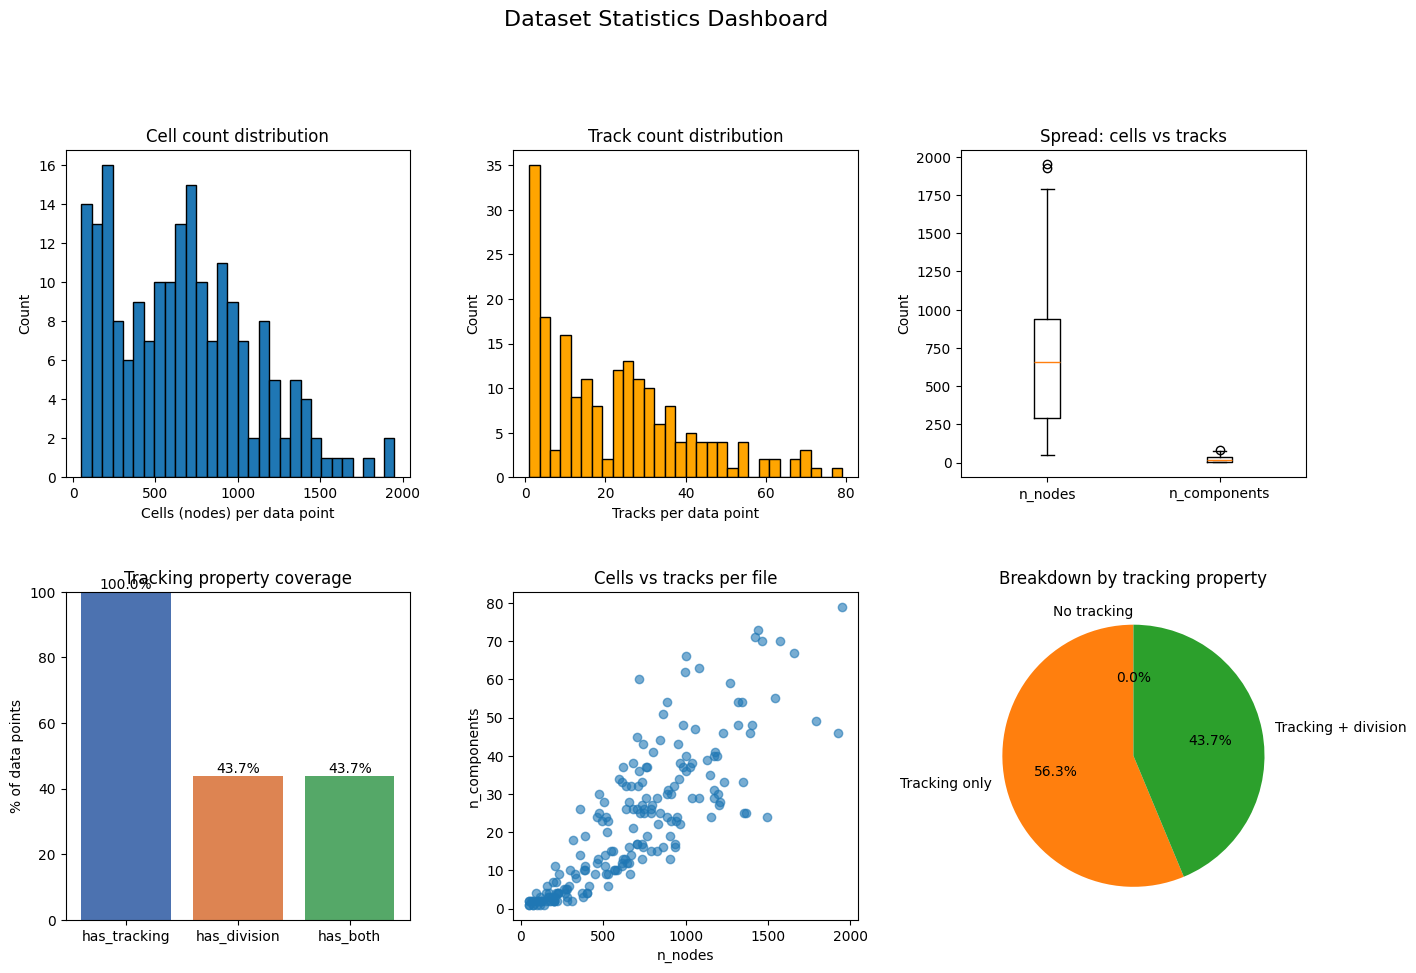

In [37]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(16, 10))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.35, wspace=0.3)

# 1. Histogram: cells per data point
ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(df.n_nodes, bins=30, edgecolor='black')
ax1.set_xlabel("Cells (nodes) per data point")
ax1.set_ylabel("Count")
ax1.set_title("Cell count distribution")

# 2. Histogram: tracks per data point
ax2 = fig.add_subplot(gs[0, 1])
ax2.hist(df.n_components, bins=30, edgecolor='black', color='orange')
ax2.set_xlabel("Tracks per data point")
ax2.set_ylabel("Count")
ax2.set_title("Track count distribution")

# 3. Boxplot: nodes vs components
ax3 = fig.add_subplot(gs[0, 2])
ax3.boxplot([df.n_nodes, df.n_components], labels=["n_nodes", "n_components"])
ax3.set_ylabel("Count")
ax3.set_title("Spread: cells vs tracks")

# 4. Bar chart: coverage flags
ax4 = fig.add_subplot(gs[1, 0])
flags = ["has_tracking", "has_division", "has_both"]
pcts = [100 * df[f].sum() / len(df) for f in flags]
bars = ax4.bar(flags, pcts, color=['#4C72B0', '#DD8452', '#55A868'])
ax4.set_ylabel("% of data points")
ax4.set_ylim(0, 100)
ax4.set_title("Tracking property coverage")
for bar, pct in zip(bars, pcts):
    ax4.text(bar.get_x() + bar.get_width()/2, pct + 1, f"{pct:.1f}%", ha='center')

# 5. Scatter: nodes vs components
ax5 = fig.add_subplot(gs[1, 1])
ax5.scatter(df.n_nodes, df.n_components, alpha=0.6)
ax5.set_xlabel("n_nodes")
ax5.set_ylabel("n_components")
ax5.set_title("Cells vs tracks per file")

# 6. Pie chart: breakdown
ax6 = fig.add_subplot(gs[1, 2])
labels = ["No tracking", "Tracking only", "Tracking + division"]
sizes = [
    len(df) - df.has_tracking.sum(),
    df.has_tracking.sum() - df.has_both.sum(),
    df.has_both.sum(),
]
ax6.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)
ax6.set_title("Breakdown by tracking property")

fig.suptitle("Dataset Statistics Dashboard", fontsize=16, y=1.02)
plt.savefig("dashboard.png", dpi=150, bbox_inches='tight')
plt.show()